# 14 — ablation des micro-boosts

Post-traitement sur les CSV de `data/hybrid_pred`. Aucun poids n'est réappris.

Quatre briques du notebook `rsna-knee-0-956-micro-boost-clinical-tri-reader`, dans l'ordre du code :

1. **Température** — `z / 1.02`, puis clip à ±3,5
2. **Latéralité** — Lateral OA et Lateral Meniscus reçoivent 12 % du z médial homologue
3. **Cross-prior** — contusion pousse l'ACL, ménisque médial pousse l'OA médiale, épanchement pousse la synovite. Hausse seulement, plafonnée
4. **Consensus** — `Φ(z) + 1e-5 × moyenne des probabilités brutes`, puis re-rang

Le mélange de départ est **uniforme** en espace probit (rang dans le split, puis `Φ⁻¹`, puis moyenne). La matrice de routage du notebook source (ConvNeXt à 0,52 sur Lateral OA, etc.) reste dehors : elle décrit ses trois lecteurs.

Même population que le notebook 13. Labels v3b binarisés à 0,5, gold officiel pour les 58. Le chiffre de décision est la macro-AUC **val**. Gold est un contrôle.

Les rangs sont calculés dans le split scoré. `T = 1,02` est monotone. Sur 652 études le probit du rang extrême vaut environ 3,2, donc le clip ±3,5 ne s'active pas. Le consensus `1e-5` ne départage que des ex-aequo. Latéralité et cross-prior sont les deux briques qui mélangent une colonne dans une autre.

Commenter une ligne de `MODELS` retire un modèle.


In [1]:
from __future__ import annotations

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.special import ndtr, ndtri

%matplotlib inline
plt.rcParams["figure.dpi"] = 100

ROOT = Path.cwd() if (Path.cwd() / "checkpoints").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

from src.nlp.lexicon import TARGETS
from src.train.metrics import macro_auc

PRED = ROOT / "data" / "hybrid_pred"

# Seul levier de modèles : commenter une ligne en retire un.
MODELS = [
    ("ViT-k320", "hybrid_preds_unseen_rsna_vitkllrd08.csv"),
    ("v20h", "hybrid_preds_unseen_rsna__subset_v20h_dino_ep11_v3b_hybrid025.csv"),
    # ("v20h-c145", "hybrid_preds_unseen_rsna__subset_v20h_dino_ep11_v3b_hybrid025_wd01_crop145.csv"),
    ("CoAt-a", "hybrid_preds_unseen_rsna__subset_coat_a_llrd08_v3b_hybrid025.csv"),
    # ("CNX-r7", "hybrid_preds_unseen_rsna__subset_cnx_r7_in22k_v3b_hybrid025.csv"),
    # ("v20h-distil", "hybrid_preds_unseen_rsna__subset_v20h_dino_ep11_v3b_rsna1687_distil_main_crop145.csv"),
]

# Coefficients du notebook source.
T_DAMP = 1.02
Z_CLIP = 3.5
LAT_KEEP = 0.88
TIE_EPS = 1e-5
PRIORS = (
    # cible, source, gain, plafond
    ("ACL", "Contusion", 0.04, 0.08),
    ("Medial OA", "Medial Meniscus", 0.03, 0.06),
    ("Synovitis", "Effusion", 0.03, 0.06),
)
LAT_PAIRS = (
    ("Lateral OA", "Medial OA"),
    ("Lateral Meniscus", "Medial Meniscus"),
)

print("ROOT", ROOT)
print("modèles", [name for name, _ in MODELS])


ROOT C:\Users\sulta\Documents\RSNA-comp
modèles ['ViT-k320', 'v20h', 'CoAt-a']


In [2]:
slots = pd.read_csv(PRED / "slot_empty_unseen_rsna.csv")
uids = slots.StudyInstanceUID.astype(str).tolist()
frames = []
for name, fn in MODELS:
    df = pd.read_csv(PRED / fn)
    got = df.StudyInstanceUID.astype(str).tolist()
    if got != uids:
        raise SystemExit(f"{name} : ordre des UID différent de slot_empty")
    frames.append(df)

v3 = pd.read_csv(ROOT / "data/labels/coolin/targets_v3b.csv")
v3["StudyInstanceUID"] = v3.StudyInstanceUID.astype(str)
lab = v3.set_index("StudyInstanceUID")[TARGETS]
gold_df = pd.read_csv(ROOT / "data/csv/train.csv", usecols=["StudyInstanceUID"] + TARGETS)
gold_df["StudyInstanceUID"] = gold_df.StudyInstanceUID.astype(str)
gold_lab = gold_df.dropna(subset=TARGETS).set_index("StudyInstanceUID")[TARGETS]

rows, labeled = [], []
for uid, sp in zip(uids, slots["split"].astype(str)):
    src = gold_lab if sp == "gold" else lab
    if uid not in src.index or src.loc[uid, TARGETS].isna().any():
        labeled.append(False)
        rows.append(np.full(len(TARGETS), np.nan))
    else:
        labeled.append(True)
        rows.append(src.loc[uid, TARGETS].to_numpy(np.float64))
y_soft = np.vstack(rows)
labeled = np.asarray(labeled)
y_hard = (y_soft >= 0.5).astype(np.float64)

split = slots["split"].astype(str).to_numpy()
val_m = (split == "val") & labeled
gold_m = (split == "gold") & labeled
model_probs = [df[[f"proba_{t}" for t in TARGETS]].to_numpy(np.float64) for df in frames]
names = [name for name, _ in MODELS]

print(
    f"études {len(uids)} | val {int(val_m.sum())} | gold {int(gold_m.sum())}"
)
print("taux positifs val")
print(pd.Series(y_hard[val_m].mean(0), index=TARGETS).round(3).to_string())


études 3142 | val 652 | gold 58
taux positifs val
ACL                 0.089
MCL                 0.028
Medial Meniscus     0.377
Lateral Meniscus    0.149
Medial OA           0.232
Lateral OA          0.097
PF OA               0.408
Effusion            0.466
Synovitis           0.094
Baker's             0.219
Contusion           0.090
Fracture            0.032


## Transforms

`z` est la moyenne des probits des rangs. Chaque variante isolée part de ce `z`. Le cumul suit l'ordre du notebook : température, latéralité, cross-prior, retour en probabilité, consensus.


In [3]:
def to_pct(p: np.ndarray) -> np.ndarray:
    n = len(p)
    r = pd.DataFrame(p).rank(method="average", axis=0).to_numpy()
    return np.clip((r - 0.5) / n, 1e-6, 1.0 - 1e-6)


def _col() -> dict[str, int]:
    return {t: i for i, t in enumerate(TARGETS)}


def damp(z: np.ndarray) -> np.ndarray:
    return np.clip(z / T_DAMP, -Z_CLIP, Z_CLIP)


def laterality(z: np.ndarray, keep: float = LAT_KEEP) -> np.ndarray:
    if keep == 1.0:
        return z
    out = z.copy()
    ix = _col()
    for dst, src in LAT_PAIRS:
        out[:, ix[dst]] = keep * out[:, ix[dst]] + (1.0 - keep) * out[:, ix[src]]
    return out


def cross_prior(z: np.ndarray, scale: float = 1.0) -> np.ndarray:
    if scale == 0.0:
        return z
    out = z.copy()
    ix = _col()
    for dst, src, gain, cap in PRIORS:
        lift = np.clip((out[:, ix[src]] - 0.5) * gain * scale, 0.0, cap * scale)
        out[:, ix[dst]] = out[:, ix[dst]] + lift
    return out


def tie_break(p_fused: np.ndarray, raw_mean: np.ndarray) -> np.ndarray:
    return to_pct(p_fused + TIE_EPS * raw_mean)


def blend_probit(probs: list[np.ndarray]) -> tuple[np.ndarray, np.ndarray]:
    z = np.mean([ndtri(to_pct(p)) for p in probs], axis=0)
    return z, np.mean(probs, axis=0)


def variants(probs: list[np.ndarray]) -> tuple[dict[str, np.ndarray], int]:
    z, raw_mean = blend_probit(probs)
    n_clip = int(np.sum(np.abs(z) > Z_CLIP))

    def back(zz: np.ndarray, tie: bool = False) -> np.ndarray:
        p = ndtr(zz)
        return tie_break(p, raw_mean) if tie else p

    z_t = damp(z)
    return {
        "proba": raw_mean,
        "rang": np.mean([to_pct(p) for p in probs], axis=0),
        "probit": back(z),
        "T": back(z_t),
        "lat": back(laterality(z)),
        "prior": back(cross_prior(z)),
        "tie": back(z, tie=True),
        "cumul_T": back(z_t),
        "cumul_T_lat": back(laterality(z_t)),
        "cumul_T_lat_prior": back(cross_prior(laterality(z_t))),
        "cumul_tout": back(cross_prior(laterality(z_t)), tie=True),
    }, n_clip


ISO = ["proba", "rang", "probit", "T", "lat", "prior", "tie"]
CUM = ["probit", "cumul_T", "cumul_T_lat", "cumul_T_lat_prior", "cumul_tout"]
PRETTY = {
    "proba": "moyenne des probabilités",
    "rang": "moyenne des rangs",
    "probit": "probit uniforme",
    "T": "probit + T",
    "lat": "probit + latéralité",
    "prior": "probit + cross-prior",
    "tie": "probit + consensus",
    "cumul_T": "probit → T",
    "cumul_T_lat": "→ + latéralité",
    "cumul_T_lat_prior": "→ + cross-prior",
    "cumul_tout": "→ + consensus",
}


def score_mask(mask: np.ndarray):
    probs = [p[mask] for p in model_probs]
    y = y_hard[mask]
    scores, n_clip = variants(probs)
    macros, pers = {}, {}
    for key, s in scores.items():
        macros[key], pers[key] = macro_auc(y, s, TARGETS)
    singles = {}
    for name, p in zip(names, model_probs):
        singles[name] = macro_auc(y, p[mask], TARGETS)[0]
    return macros, pers, singles, n_clip


val_auc, val_per, val_single, n_clip_val = score_mask(val_m)
gold_auc, gold_per, gold_single, n_clip_gold = score_mask(gold_m)

# T monotone et clip inactif : l'AUC par cible reste celle du probit.
# Latéralité et cross-prior ne touchent que leurs cibles.
for t in TARGETS:
    if abs(val_per["T"][t] - val_per["probit"][t]) > 1e-12:
        raise SystemExit(f"T a bougé {t}")
    if t not in ("Lateral OA", "Lateral Meniscus"):
        if val_per["lat"][t] != val_per["probit"][t]:
            raise SystemExit(f"latéralité a bougé {t}")
    if t not in ("ACL", "Medial OA", "Synovitis"):
        if val_per["prior"][t] != val_per["probit"][t]:
            raise SystemExit(f"cross-prior a bougé {t}")

print(f"cellules |z| > {Z_CLIP} avant clip : val {n_clip_val} | gold {n_clip_gold}")
print("modèles, macro-AUC")
for name in names:
    print(f"  {name:12s}  val {val_single[name]:.4f}  gold {gold_single[name]:.4f}")


cellules |z| > 3.5 avant clip : val 0 | gold 0
modèles, macro-AUC
  ViT-k320      val 0.9199  gold 0.8409
  v20h          val 0.9551  gold 0.9124
  CoAt-a        val 0.9041  gold 0.8591


## Val, une brique à la fois

`d_proba` et `d_probit` sont des écarts de macro-AUC sur la val. Gold est le même pipeline, rangs recalculés sur les 58.


In [4]:
def _table(keys: list[str]) -> pd.DataFrame:
    rows = []
    for key in keys:
        rows.append({
            "variante": PRETTY[key],
            "val": val_auc[key],
            "d_proba": val_auc[key] - val_auc["proba"],
            "d_probit": val_auc[key] - val_auc["probit"],
            "gold": gold_auc[key],
        })
    return pd.DataFrame(rows)


show_iso = _table(ISO)
show_cum = _table(CUM)
print("isolé")
print(show_iso.round(4).to_string(index=False))
print()
print("cumul")
print(show_cum.round(4).to_string(index=False))


isolé
                variante    val  d_proba  d_probit   gold
moyenne des probabilités 0.9524   0.0000    0.0070 0.9016
       moyenne des rangs 0.9432  -0.0093   -0.0023 0.8892
         probit uniforme 0.9454  -0.0070    0.0000 0.8887
              probit + T 0.9454  -0.0070    0.0000 0.8887
     probit + latéralité 0.9443  -0.0081   -0.0011 0.8875
    probit + cross-prior 0.9454  -0.0070   -0.0000 0.8886
      probit + consensus 0.9454  -0.0070    0.0000 0.8888

cumul
       variante    val  d_proba  d_probit   gold
probit uniforme 0.9454  -0.0070    0.0000 0.8887
     probit → T 0.9454  -0.0070    0.0000 0.8887
 → + latéralité 0.9443  -0.0081   -0.0011 0.8875
→ + cross-prior 0.9443  -0.0081   -0.0012 0.8874
  → + consensus 0.9443  -0.0081   -0.0012 0.8874


## Val, par cible

Écart contre le probit uniforme. Une cible absente de la brique reste à zéro : le score de cette colonne n'a pas changé.


In [5]:
touched = {
    "lat": ("Lateral OA", "Lateral Meniscus"),
    "prior": ("ACL", "Medial OA", "Synovitis"),
}
rows = []
for target in TARGETS:
    row = {
        "cible": target,
        "proba": val_per["proba"][target],
        "probit": val_per["probit"][target],
        "d_lat": val_per["lat"][target] - val_per["probit"][target],
        "d_prior": val_per["prior"][target] - val_per["probit"][target],
        "d_tout": val_per["cumul_tout"][target] - val_per["probit"][target],
    }
    rows.append(row)
per = pd.DataFrame(rows).set_index("cible")
print(per.round(4).to_string())
print()
print("cibles touchées")
for key, cols in touched.items():
    for target in cols:
        d = val_per[key][target] - val_per["probit"][target]
        g = gold_per[key][target] - gold_per["probit"][target]
        print(f"  {key:6s} {target:20s}  val {d:+.4f}  gold {g:+.4f}")


                   proba  probit   d_lat  d_prior  d_tout
cible                                                    
ACL               0.9268  0.9240  0.0000  -0.0008 -0.0008
MCL               0.9329  0.8817  0.0000   0.0000  0.0000
Medial Meniscus   0.9816  0.9788  0.0000   0.0000  0.0000
Lateral Meniscus  0.9474  0.9378 -0.0108   0.0000 -0.0108
Medial OA         0.9617  0.9594  0.0000   0.0005  0.0005
Lateral OA        0.9410  0.9386 -0.0025   0.0000 -0.0025
PF OA             0.8902  0.8870  0.0000   0.0000  0.0000
Effusion          0.9630  0.9613  0.0000   0.0000  0.0000
Synovitis         0.9514  0.9501  0.0000  -0.0004 -0.0004
Baker's           0.9750  0.9733  0.0000   0.0000  0.0000
Contusion         0.9851  0.9794  0.0000   0.0000  0.0000
Fracture          0.9732  0.9740  0.0000   0.0000  0.0000

cibles touchées
  lat    Lateral OA            val -0.0025  gold +0.0010
  lat    Lateral Meniscus      val -0.0108  gold -0.0161
  prior  ACL                   val -0.0008  gold +0.0000


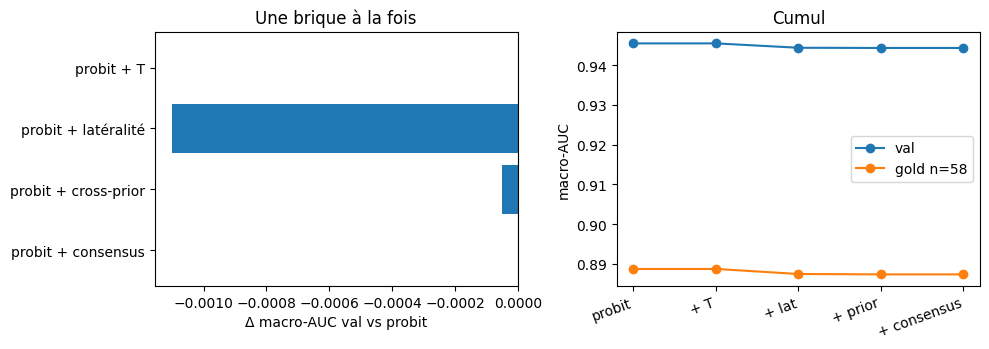

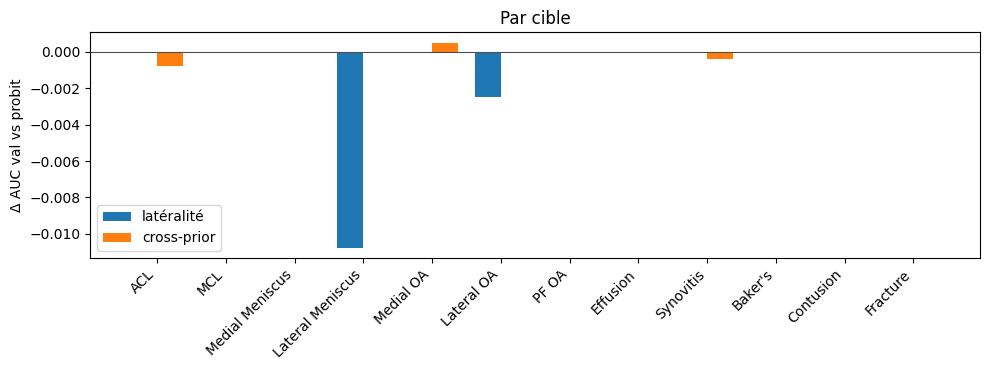

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))

iso_keys = ["T", "lat", "prior", "tie"]
deltas = [val_auc[k] - val_auc["probit"] for k in iso_keys]
axes[0].barh([PRETTY[k] for k in iso_keys][::-1], deltas[::-1], color="C0")
axes[0].axvline(0, color="0.3", lw=0.8)
axes[0].set_xlabel("Δ macro-AUC val vs probit")
axes[0].set_title("Une brique à la fois")

axes[1].plot(
    range(len(CUM)),
    [val_auc[k] for k in CUM],
    marker="o",
    label="val",
)
axes[1].plot(
    range(len(CUM)),
    [gold_auc[k] for k in CUM],
    marker="o",
    label="gold n=58",
)
axes[1].set_xticks(
    range(len(CUM)),
    ["probit", "+ T", "+ lat", "+ prior", "+ consensus"],
    rotation=20,
    ha="right",
)
axes[1].set_ylabel("macro-AUC")
axes[1].set_title("Cumul")
axes[1].legend()
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 3.8))
x = np.arange(len(TARGETS))
w = 0.38
ax.bar(x - w / 2, per["d_lat"], w, label="latéralité")
ax.bar(x + w / 2, per["d_prior"], w, label="cross-prior")
ax.axhline(0, color="0.3", lw=0.8)
ax.set_xticks(x, TARGETS, rotation=45, ha="right")
ax.set_ylabel("Δ AUC val vs probit")
ax.set_title("Par cible")
ax.legend()
fig.tight_layout()
plt.show()


## Sensibilité val

Grille sur le poids latéral gardé (`1,00` = pas de mélange) et le multiplicateur du cross-prior (`0` = prior éteint). Le point publié est `0,88` et `1×`. La grille est lue sur la val ; elle ne choisit pas un coefficient pour le gold.


Δ macro-AUC val vs probit
           prior ×0  prior ×0.5  prior ×1  prior ×2
keep 1.00    0.0000     -0.0000   -0.0000   -0.0001
keep 0.94   -0.0005     -0.0005   -0.0005   -0.0006
keep 0.88   -0.0011     -0.0011   -0.0012   -0.0012
keep 0.76   -0.0028     -0.0028   -0.0028   -0.0029
point publié (keep 0.88, prior ×1) : val 0.9443  (-0.0012)


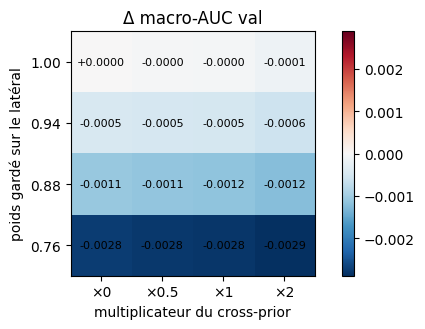

In [7]:
keeps = (1.0, 0.94, 0.88, 0.76)
scales = (0.0, 0.5, 1.0, 2.0)
probs_val = [p[val_m] for p in model_probs]
z_val, _ = blend_probit(probs_val)
y_val = y_hard[val_m]
base = val_auc["probit"]

grid = np.zeros((len(keeps), len(scales)))
for i, keep in enumerate(keeps):
    for j, scale in enumerate(scales):
        score = ndtr(cross_prior(laterality(z_val, keep), scale))
        grid[i, j] = macro_auc(y_val, score, TARGETS)[0]

if abs(grid[0, 0] - base) > 1e-12:
    raise SystemExit("le coin identité de la grille ne retrouve pas le probit")

delta = grid - base
show = pd.DataFrame(
    delta,
    index=[f"keep {k:.2f}" for k in keeps],
    columns=[f"prior ×{s:g}" for s in scales],
)
print("Δ macro-AUC val vs probit")
print(show.round(4).to_string())
print(f"point publié (keep 0.88, prior ×1) : val {grid[2, 2]:.4f}  ({delta[2, 2]:+.4f})")

fig, ax = plt.subplots(figsize=(6.2, 3.4))
lim = max(0.0015, float(np.max(np.abs(delta))))
im = ax.imshow(delta, cmap="RdBu_r", vmin=-lim, vmax=lim)
ax.set_xticks(range(len(scales)), [f"×{s:g}" for s in scales])
ax.set_yticks(range(len(keeps)), [f"{k:.2f}" for k in keeps])
ax.set_xlabel("multiplicateur du cross-prior")
ax.set_ylabel("poids gardé sur le latéral")
for i in range(len(keeps)):
    for j in range(len(scales)):
        ax.text(j, i, f"{delta[i, j]:+.4f}", ha="center", va="center", fontsize=8)
ax.set_title("Δ macro-AUC val")
fig.colorbar(im, ax=ax, fraction=0.046)
fig.tight_layout()
plt.show()
